# Customer Churn — Exploratory Data Analysis

**Phase 3 scope:** describe customers and examine churn associations using only the fixed Phase 2 training partition. This notebook does not engineer features, fit models, tune parameters, evaluate the final test set, or simulate retention targeting.

## Analytical safeguards

The cleaned dataset and saved split must already exist. If the split is absent or its fingerprint is invalid, execution stops instead of creating a different split. The final 240 test rows are never summarized or plotted. All findings are observational associations, not evidence that a customer characteristic causes churn. Missing values and unusual observations remain unchanged.

## 1. Setup, theme, and reusable helpers

A consistent blue-and-purple theme and shared helper functions keep the figures presentation-ready and the calculations reproducible.

In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in candidate_roots if (path / "src" / "preprocessing.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    create_or_load_fixed_split,
    get_feature_groups,
    load_and_validate_data,
)

CLEANED_PATH = PROJECT_ROOT / "data" / "processed" / "02_cleaned_dataset.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "02_split_indices.json"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

BLUE = "#2563EB"
LIGHT_BLUE = "#60A5FA"
PURPLE = "#7C3AED"
LIGHT_PURPLE = "#A78BFA"
GRAY = "#64748B"
CHURN_COLORS = {"Retained (0)": BLUE, "Churned (1)": PURPLE}
BLUE_PURPLE_CMAP = sns.blend_palette(["#EFF6FF", LIGHT_BLUE, PURPLE], as_cmap=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

def churn_summary(data, group_column):
    return (
        data.groupby(group_column, observed=True)["churn"]
        .agg(customer_count="size", churn_count="sum", churn_rate_pct=lambda values: values.mean() * 100)
        .reset_index()
    )

def label_rate_bars(ax, summary):
    for bar, row in zip(ax.patches, summary.itertuples(index=False)):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.0,
            f"{row.churn_rate_pct:.1f}%\nn={row.customer_count:,}",
            ha="center", va="bottom", fontsize=9,
        )

def save_figure(fig, filename):
    output_path = FIGURES_DIR / filename
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {output_path.relative_to(PROJECT_ROOT)}")

## 2. Load the exact Phase 2 training partition

The split loader validates the dataset fingerprint, row count, test size, and random seed. The explicit existence check prevents it from creating a replacement if the saved artifact is missing. Only training indices are used to construct `train_df`; no held-out dataframe is created.

In [2]:
if not CLEANED_PATH.is_file():
    raise FileNotFoundError("Phase 2 cleaned dataset is missing. Stop instead of recreating it.")
if not SPLIT_PATH.is_file():
    raise FileNotFoundError("Phase 2 split artifact is missing. Stop instead of creating a new split.")

cleaned_sha256_before = hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest()
cleaned_df = load_and_validate_data(CLEANED_PATH)
split = create_or_load_fixed_split(
    cleaned_df, SPLIT_PATH, test_size=0.20, random_state=42
)
if not split["loaded_existing"]:
    raise RuntimeError("EDA requires the previously saved Phase 2 split.")

train_indices = split["train_indices"]
test_indices = split["test_indices"]
assert set(train_indices).isdisjoint(test_indices)
train_df = cleaned_df.iloc[train_indices].copy()

print(f"Training rows used for EDA: {len(train_df):,}")
print(f"Held-out rows kept sealed: {len(test_indices):,}")
print(f"Dataset fingerprint: {split['dataset_fingerprint']}")
print(f"Random seed: {split['random_state']}")

Training rows used for EDA: 960
Held-out rows kept sealed: 240
Dataset fingerprint: df788deba598b73abdc3a41b8a1947af63a90c5f369c2a498386a2c0eefeb769
Random seed: 42


## 3. Training dataset overview

We first inspect dimensions, types, feature roles, descriptive statistics, category sizes, and missingness. Customer IDs are not displayed or analyzed. The unresolved charge/service relationships and outliers remain documented constraints rather than cleaning instructions.

In [3]:
numerical_features, categorical_features = get_feature_groups(train_df)
print(f"Training dimensions: {train_df.shape[0]:,} rows × {train_df.shape[1]} columns")
print(f"Numerical predictors ({len(numerical_features)}): {numerical_features}")
print(f"Categorical predictors ({len(categorical_features)}): {categorical_features}")
display(pd.DataFrame({"dtype": train_df.dtypes.astype(str), "non_missing": train_df.notna().sum()}))
display(train_df[numerical_features].describe().T)

category_overview = []
for column in categorical_features:
    counts = train_df[column].value_counts(dropna=False)
    category_overview.append({
        "column": column,
        "distinct_non_missing": train_df[column].nunique(dropna=True),
        "most_common": counts.index[0],
        "most_common_count": counts.iloc[0],
    })
display(pd.DataFrame(category_overview).set_index("column"))
for column in categorical_features:
    distribution = train_df[column].value_counts(dropna=False).rename("count").to_frame()
    distribution["percentage"] = distribution["count"].div(len(train_df)).mul(100)
    print(f"\n{column}")
    display(distribution)

training_missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_pct": train_df.isna().mean().mul(100),
}).query("missing_count > 0").sort_values("missing_count", ascending=False)
print("Training-partition missingness")
display(training_missing)
print(f"Rows with any missing value: {train_df.isna().any(axis=1).sum():,}")

Training dimensions: 960 rows × 20 columns
Numerical predictors (9): ['age', 'tenure_months', 'monthly_charges', 'total_charges', 'complaints_last_12m', 'late_payments_last_12m', 'satisfaction_score', 'monthly_usage_gb', 'discount_pct']
Categorical predictors (9): ['contract_type', 'internet_service', 'region', 'payment_method', 'paperless_billing', 'dependents', 'support_plan', 'tech_support', 'senior_citizen']


,dtype,non_missing
customer_id,str,960
age,int64,960
tenure_months,int64,960
contract_type,str,960
internet_service,str,960
region,str,960
monthly_charges,float64,932
total_charges,float64,940
payment_method,str,960
paperless_billing,str,960


,count,mean,std,min,25%,50%,75%,max
age,960.00,46.69,16.70,18.00,33.00,47.00,62.00,75.00
tenure_months,960.00,35.86,21.13,1.00,18.00,35.00,54.00,72.00
monthly_charges,932.00,70.91,25.35,20.00,54.25,71.21,86.46,235.01
total_charges,940.00,"2,533.57","1,826.01",22.73,"1,050.23","2,175.62","3,772.93","8,853.76"
complaints_last_12m,960.00,0.71,0.86,0.00,0.00,1.00,1.00,5.00
late_payments_last_12m,960.00,0.82,0.87,0.00,0.00,1.00,1.00,4.00
satisfaction_score,922.00,6.80,1.75,1.60,5.70,6.80,8.00,10.00
monthly_usage_gb,937.00,65.98,38.79,2.00,41.10,65.00,88.10,451.30
discount_pct,960.00,9.14,6.68,0.00,3.49,8.55,13.81,32.89


,distinct_non_missing,most_common,most_common_count
column,,,
contract_type,3,Month-to-month,562
internet_service,3,Fiber optic,496
region,9,Central,119
payment_method,4,Electronic check,318
paperless_billing,2,Yes,637
dependents,2,No,668
support_plan,2,No,556
tech_support,2,No,583
senior_citizen,2,0,792



contract_type


...


senior_citizen


,count,percentage
senior_citizen,,
0,792,82.50
1,168,17.50


Training-partition missingness


,missing_count,missing_pct
satisfaction_score,38,3.96
monthly_charges,28,2.92
monthly_usage_gb,23,2.40
total_charges,20,2.08


Rows with any missing value: 103


## 4. Churn distribution

The target balance establishes the baseline context for every later percentage.

,status,count,percentage
0,Retained (0),131,13.65
1,Churned (1),829,86.35


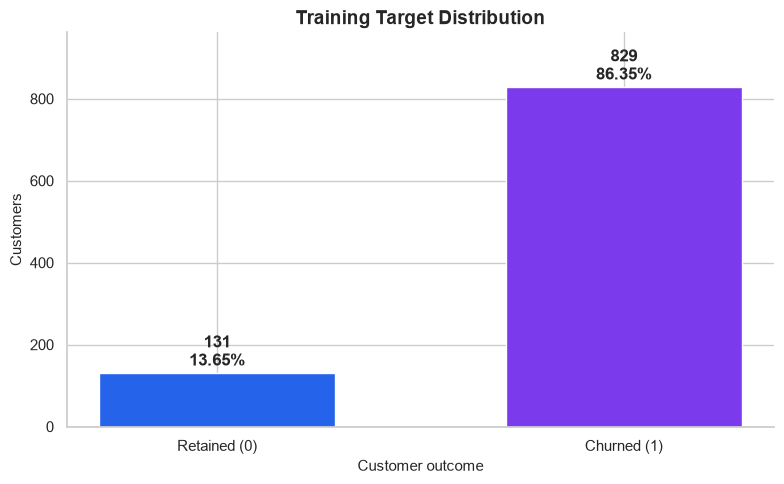

Saved: reports\figures\01_churn_distribution.png


In [4]:
target_summary = (
    train_df["churn"].value_counts().sort_index().rename_axis("churn").reset_index(name="count")
)
target_summary["status"] = target_summary["churn"].map({0: "Retained (0)", 1: "Churned (1)"})
target_summary["percentage"] = target_summary["count"].div(len(train_df)).mul(100)
display(target_summary[["status", "count", "percentage"]])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(target_summary["status"], target_summary["count"], color=[BLUE, PURPLE], width=0.58)
for bar, row in zip(bars, target_summary.itertuples(index=False)):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 18, f"{row.count:,}\n{row.percentage:.2f}%", ha="center", fontweight="bold")
ax.set(title="Training Target Distribution", xlabel="Customer outcome", ylabel="Customers")
ax.set_ylim(0, target_summary["count"].max() * 1.16)
sns.despine(ax=ax)
save_figure(fig, "01_churn_distribution.png")

### Interpretation

The training data contains **829 churned customers (86.35%)** and **131 retained customers (13.65%)**. A rule that labels everyone as churned would already be 86.35% accurate, so accuracy alone would hide failure on the smaller retained class. Later modeling should use class-specific precision/recall, F1, PR-AUC, ROC-AUC, and business ranking measures. The unusually high churn prevalence may reflect population selection or label semantics and still requires confirmation; the chart does not establish why churn is high.

## 5. Contract type versus churn

,contract_type,customer_count,churn_count,churn_rate_pct
0,Month-to-month,562,512,91.10
1,One year,245,196,80.00
2,Two year,153,121,79.08


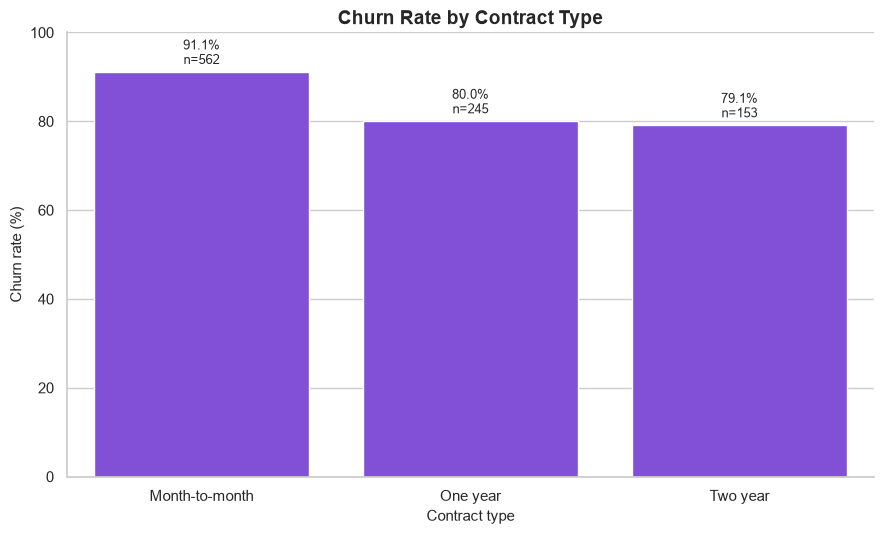

Saved: reports\figures\02_contract_churn.png


In [5]:
contract_order = ["Month-to-month", "One year", "Two year"]
contract_summary = churn_summary(train_df, "contract_type").set_index("contract_type").loc[contract_order].reset_index()
display(contract_summary)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=contract_summary, x="contract_type", y="churn_rate_pct", order=contract_order, color=PURPLE, ax=ax)
label_rate_bars(ax, contract_summary)
ax.set(title="Churn Rate by Contract Type", xlabel="Contract type", ylabel="Churn rate (%)", ylim=(0, 100))
sns.despine(ax=ax)
save_figure(fig, "02_contract_churn.png")

### Interpretation

Month-to-month customers have a **91.10% churn rate (512 of 562)**, compared with **80.00% (196 of 245)** for one-year and **79.08% (121 of 153)** for two-year contracts. The 11–12 percentage-point gap is large enough to merit continued investigation and may help future risk ranking. Contract choice can be related to unobserved customer needs or tenure, so this is an association rather than proof that changing a contract prevents churn.

## 6. Tenure distribution and nonlinear churn pattern

Twelve-month intervals reflect interpretable customer-year stages and are defined without using churn outcomes.

,count,mean,50%,std
churn,,,,
Retained (0),131.00,36.69,38.00,21.09
Churned (1),829.00,35.73,34.00,21.15


,tenure_band_eda,customer_count,churn_count,churn_rate_pct
0,1–12,175,153,87.43
1,13–24,172,147,85.47
2,25–36,147,133,90.48
3,37–48,152,127,83.55
4,49–60,149,128,85.91
5,61–72,165,141,85.45


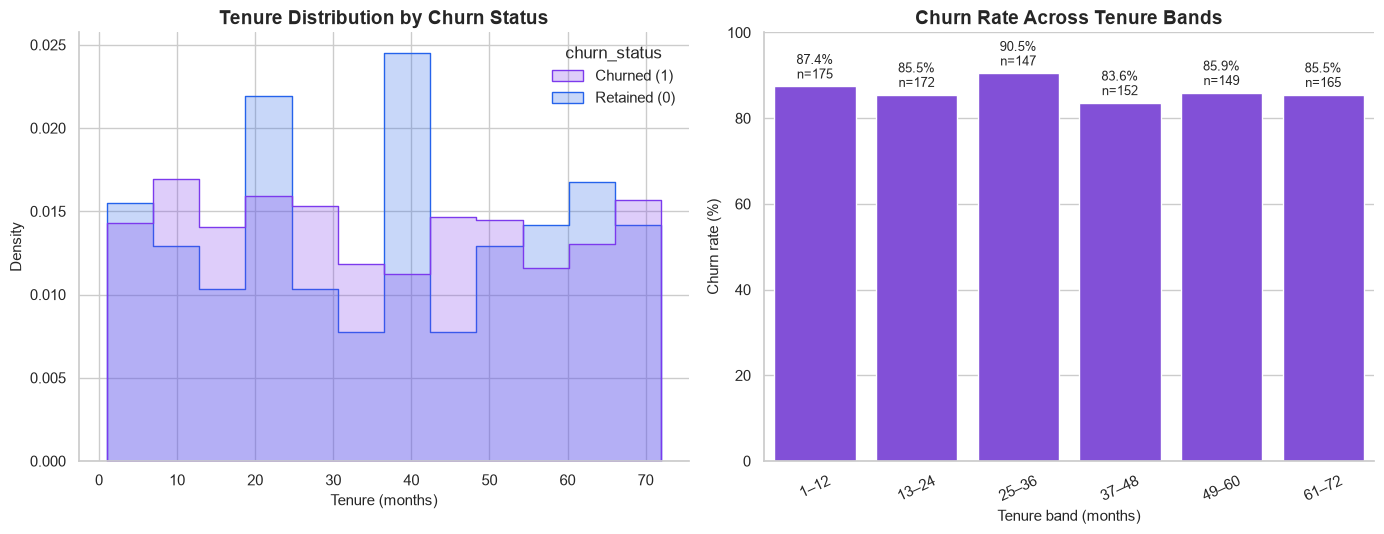

Saved: reports\figures\03_tenure_churn.png


In [6]:
status_map = {0: "Retained (0)", 1: "Churned (1)"}
tenure_labels = ["1–12", "13–24", "25–36", "37–48", "49–60", "61–72"]
train_df["tenure_band_eda"] = pd.cut(
    train_df["tenure_months"], bins=[0, 12, 24, 36, 48, 60, 72],
    labels=tenure_labels, include_lowest=True,
)
tenure_summary = churn_summary(train_df, "tenure_band_eda")
tenure_by_target = train_df.groupby("churn")["tenure_months"].describe()[["count", "mean", "50%", "std"]]
display(tenure_by_target.rename(index=status_map))
display(tenure_summary)

plot_data = train_df.assign(churn_status=train_df["churn"].map(status_map))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.histplot(data=plot_data, x="tenure_months", hue="churn_status", bins=12, element="step", stat="density", common_norm=False, palette=CHURN_COLORS, ax=axes[0])
axes[0].set(title="Tenure Distribution by Churn Status", xlabel="Tenure (months)", ylabel="Density")
sns.barplot(data=tenure_summary, x="tenure_band_eda", y="churn_rate_pct", color=PURPLE, ax=axes[1])
label_rate_bars(axes[1], tenure_summary)
axes[1].set(title="Churn Rate Across Tenure Bands", xlabel="Tenure band (months)", ylabel="Churn rate (%)", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=25)
sns.despine(fig=fig)
save_figure(fig, "03_tenure_churn.png")

### Interpretation

Churned customers have a median tenure of **34 months**, versus **38 months** for retained customers; their means are also close (35.73 versus 36.69 months). Band rates are not monotonic: they range from **83.55% for 37–48 months (n=152)** to **90.48% for 25–36 months (n=147)**, while the shortest band is 87.43%. Every band contains 147–175 customers, so the fluctuation is not driven by tiny groups. Tenure may still add predictive context or interact with contract type, but the training evidence does not support a simple claim that shorter tenure always means higher churn.

## 7. Monthly charges and nonlinear churn pattern

Training-only quintiles give similarly sized groups without selecting cut points from churn outcomes. Missing charges are excluded from this relationship but remain unchanged in the dataset.

,count,mean,50%,std
churn,,,,
Retained (0),128.00,67.76,65.79,26.84
Churned (1),804.00,71.41,72.27,25.08


Training-only quintile edges: [20.0, 50.07, 64.79, 76.77, 89.78, 235.01]


,monthly_charge_quintile_eda,customer_count,churn_count,churn_rate_pct
0,Q1 (lowest),187,153,81.82
1,Q2,186,160,86.02
2,Q3,186,157,84.41
3,Q4,186,168,90.32
4,Q5 (highest),187,166,88.77


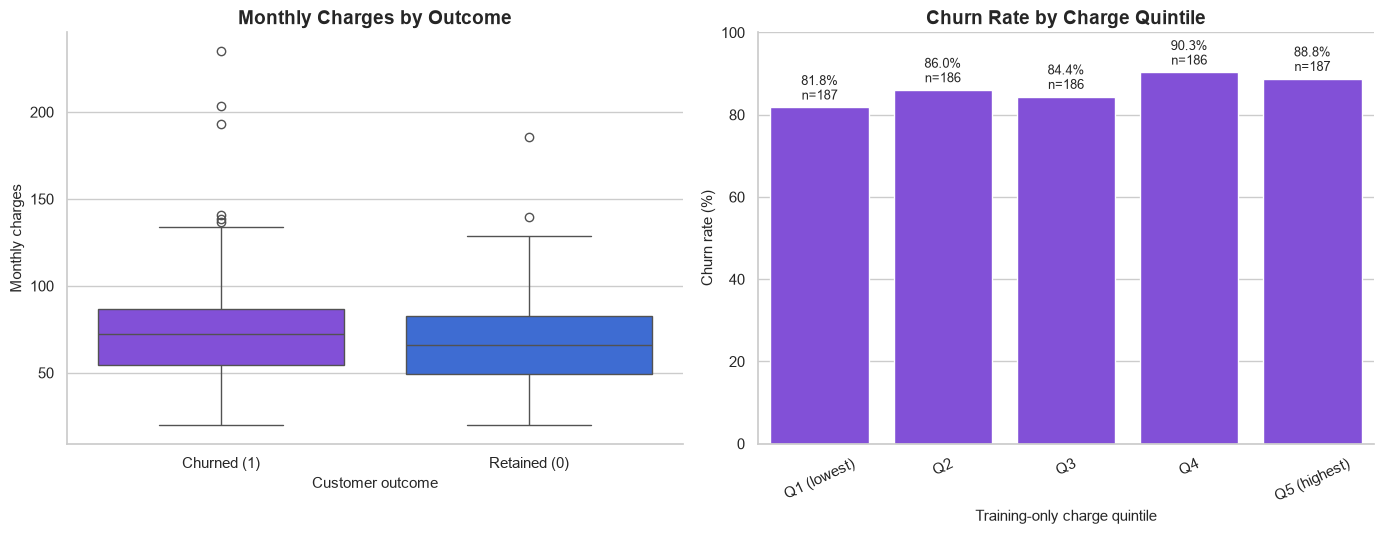

Saved: reports\figures\04_monthly_charges_churn.png


In [7]:
quintile_labels = ["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
train_df["monthly_charge_quintile_eda"], charge_edges = pd.qcut(
    train_df["monthly_charges"], q=5, labels=quintile_labels, retbins=True, duplicates="drop"
)
charge_summary = churn_summary(train_df, "monthly_charge_quintile_eda")
charge_by_target = train_df.groupby("churn")["monthly_charges"].describe()[["count", "mean", "50%", "std"]]
display(charge_by_target.rename(index=status_map))
print(f"Training-only quintile edges: {np.round(charge_edges, 2).tolist()}")
display(charge_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=plot_data, x="churn_status", y="monthly_charges", hue="churn_status", palette=CHURN_COLORS, legend=False, ax=axes[0])
axes[0].set(title="Monthly Charges by Outcome", xlabel="Customer outcome", ylabel="Monthly charges")
sns.barplot(data=charge_summary, x="monthly_charge_quintile_eda", y="churn_rate_pct", color=PURPLE, ax=axes[1])
label_rate_bars(axes[1], charge_summary)
axes[1].set(title="Churn Rate by Charge Quintile", xlabel="Training-only charge quintile", ylabel="Churn rate (%)", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=25)
sns.despine(fig=fig)
save_figure(fig, "04_monthly_charges_churn.png")

### Interpretation

Churned customers have slightly higher monthly charges: median **72.27** and mean **71.41**, versus median **65.79** and mean **67.76** for retained customers. Quintile churn rates rise from **81.82% in Q1** to **90.32% in Q4**, then ease to **88.77% in Q5**; Q3 (84.41%) is also below Q2 (86.02%). With 186–187 observed customers per quintile, this supports a modest but nonlinear association rather than an always-increasing effect. Twenty-eight training charges are missing, and charge definitions or plan mix may confound the comparison.

## 8. Satisfaction score versus churn

,count,mean,50%,std
churn,,,,
Retained (0),129.00,7.23,7.30,1.72
Churned (1),793.00,6.73,6.70,1.75


,satisfaction_band_eda,customer_count,churn_count,churn_rate_pct
0,0–2,2,2,100.00
1,>2–4,63,58,92.06
2,>4–6,223,198,88.79
3,>6–8,405,349,86.17
4,>8–10,229,186,81.22


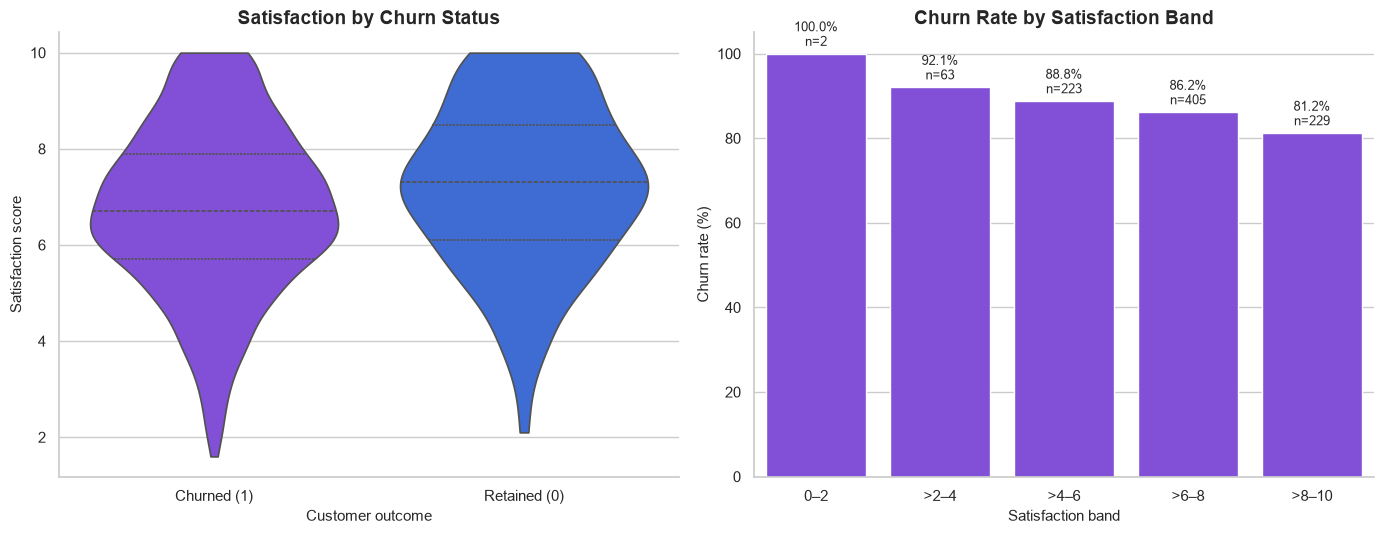

Saved: reports\figures\05_satisfaction_churn.png


In [8]:
satisfaction_labels = ["0–2", ">2–4", ">4–6", ">6–8", ">8–10"]
train_df["satisfaction_band_eda"] = pd.cut(
    train_df["satisfaction_score"], bins=[0, 2, 4, 6, 8, 10],
    labels=satisfaction_labels, include_lowest=True,
)
satisfaction_summary = churn_summary(train_df, "satisfaction_band_eda")
satisfaction_by_target = train_df.groupby("churn")["satisfaction_score"].describe()[["count", "mean", "50%", "std"]]
display(satisfaction_by_target.rename(index=status_map))
display(satisfaction_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.violinplot(data=plot_data, x="churn_status", y="satisfaction_score", hue="churn_status", palette=CHURN_COLORS, inner="quartile", cut=0, legend=False, ax=axes[0])
axes[0].set(title="Satisfaction by Churn Status", xlabel="Customer outcome", ylabel="Satisfaction score")
sns.barplot(data=satisfaction_summary, x="satisfaction_band_eda", y="churn_rate_pct", color=PURPLE, ax=axes[1])
label_rate_bars(axes[1], satisfaction_summary)
axes[1].set(title="Churn Rate by Satisfaction Band", xlabel="Satisfaction band", ylabel="Churn rate (%)", ylim=(0, 105))
sns.despine(fig=fig)
save_figure(fig, "05_satisfaction_churn.png")

### Interpretation

Churned customers average **6.73** satisfaction versus **7.23** among retained customers. Excluding the unstable 0–2 band (only two customers), churn generally declines from **92.06% in >2–4 (n=63)** to **81.22% in >8–10 (n=229)**. This ordered association could be useful, although the >4–6 and >6–8 rates remain high at 88.79% and 86.17%. Thirty-eight training scores are missing, and satisfaction timing relative to the churn outcome must be confirmed before modeling to avoid leakage.

## 9. Complaint frequency versus churn

,complaints_last_12m,customer_count,churn_count,churn_rate_pct
0,0,477,401,84.07
1,1,336,299,88.99
2,2,112,95,84.82
3,3,25,25,100.00
4,4,8,7,87.50
5,5,2,2,100.00


,customer_count,churn_count,churn_rate_pct
complaints_3plus,,,
False,925,795,85.95
True,35,34,97.14


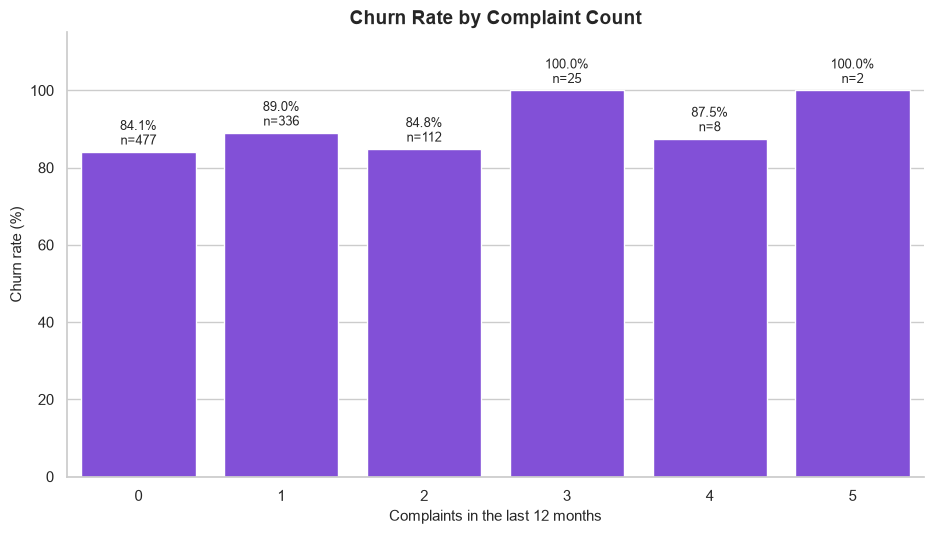

Saved: reports\figures\06_complaints_churn.png


In [9]:
complaint_summary = churn_summary(train_df, "complaints_last_12m")
complaint_aggregate = train_df.assign(complaints_3plus=train_df["complaints_last_12m"].ge(3)).groupby("complaints_3plus")["churn"].agg(customer_count="size", churn_count="sum", churn_rate_pct=lambda values: values.mean()*100)
display(complaint_summary)
display(complaint_aggregate)
fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.barplot(data=complaint_summary, x="complaints_last_12m", y="churn_rate_pct", color=PURPLE, ax=ax)
label_rate_bars(ax, complaint_summary)
ax.set(title="Churn Rate by Complaint Count", xlabel="Complaints in the last 12 months", ylabel="Churn rate (%)", ylim=(0, 115))
sns.despine(ax=ax)
save_figure(fig, "06_complaints_churn.png")

### Interpretation

Customers with no complaints churn at **84.07% (401 of 477)**, while one complaint is associated with 88.99% and two complaints with 84.82%. The individual 3–5 complaint levels fluctuate because they contain only 25, 8, and 2 customers. Aggregating those sparse levels, customers with **3+ complaints churn at 97.14% (34 of 35)** versus 85.95% below three complaints. Complaint behavior may add risk information, but the raw pattern is nonlinear and high-count estimates are uncertain.

## 10. Late-payment behavior versus churn

,late_payments_last_12m,customer_count,churn_count,churn_rate_pct
0,0,407,345,84.77
1,1,369,316,85.64
2,2,145,133,91.72
3,3,29,26,89.66
4,4,10,9,90.00


,customer_count,churn_count,churn_rate_pct
late_2plus,,,
False,776,661,85.18
True,184,168,91.30


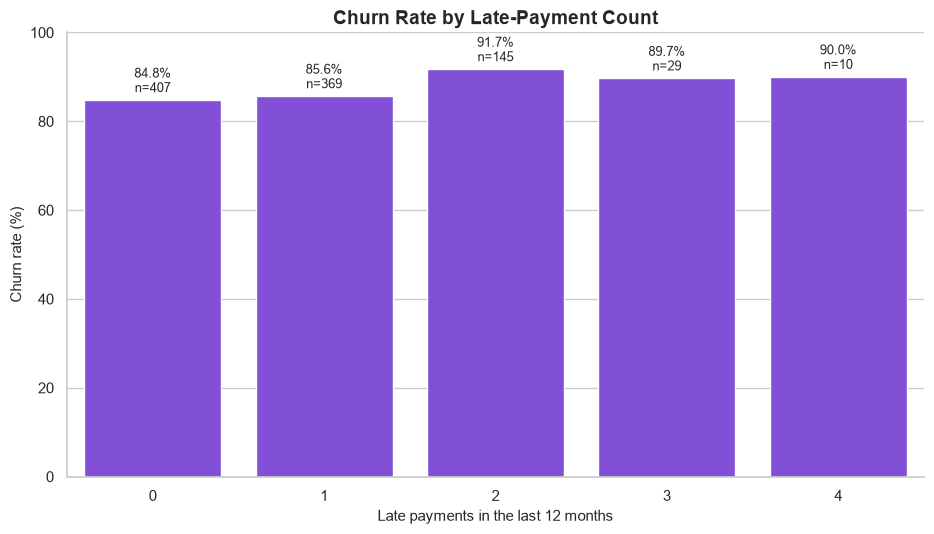

Saved: reports\figures\07_late_payments_churn.png


In [10]:
late_summary = churn_summary(train_df, "late_payments_last_12m")
late_aggregate = train_df.assign(late_2plus=train_df["late_payments_last_12m"].ge(2)).groupby("late_2plus")["churn"].agg(customer_count="size", churn_count="sum", churn_rate_pct=lambda values: values.mean()*100)
display(late_summary)
display(late_aggregate)
fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.barplot(data=late_summary, x="late_payments_last_12m", y="churn_rate_pct", color=PURPLE, ax=ax)
label_rate_bars(ax, late_summary)
ax.set(title="Churn Rate by Late-Payment Count", xlabel="Late payments in the last 12 months", ylabel="Churn rate (%)", ylim=(0, 100))
sns.despine(ax=ax)
save_figure(fig, "07_late_payments_churn.png")

### Interpretation

Churn rises from **84.77% with zero late payments (n=407)** and 85.64% with one (n=369) to 91.72% with two (n=145). The three- and four-payment rates remain near 90%, but those groups are smaller (29 and 10). In a more stable aggregation, customers with **2+ late payments churn at 91.30% (168 of 184)** versus 85.18% below two. Repeated late payment is a plausible risk marker, although financial difficulty and churn may share other causes.

## 11. Usage intensity and nonlinear churn pattern

Training-only usage quintiles are independent of churn outcomes and contain roughly equal observed samples.

,count,mean,50%,std
churn,,,,
Retained (0),127.00,30.38,28.00,22.10
Churned (1),810.00,71.57,70.75,37.88


Training-only quintile edges: [2.0, 36.02, 56.4, 73.5, 92.8, 451.3]


,usage_quintile_eda,customer_count,churn_count,churn_rate_pct
0,Q1 (lowest),188,108,57.45
1,Q2,188,155,82.45
2,Q3,188,176,93.62
3,Q4,186,185,99.46
4,Q5 (highest),187,186,99.47


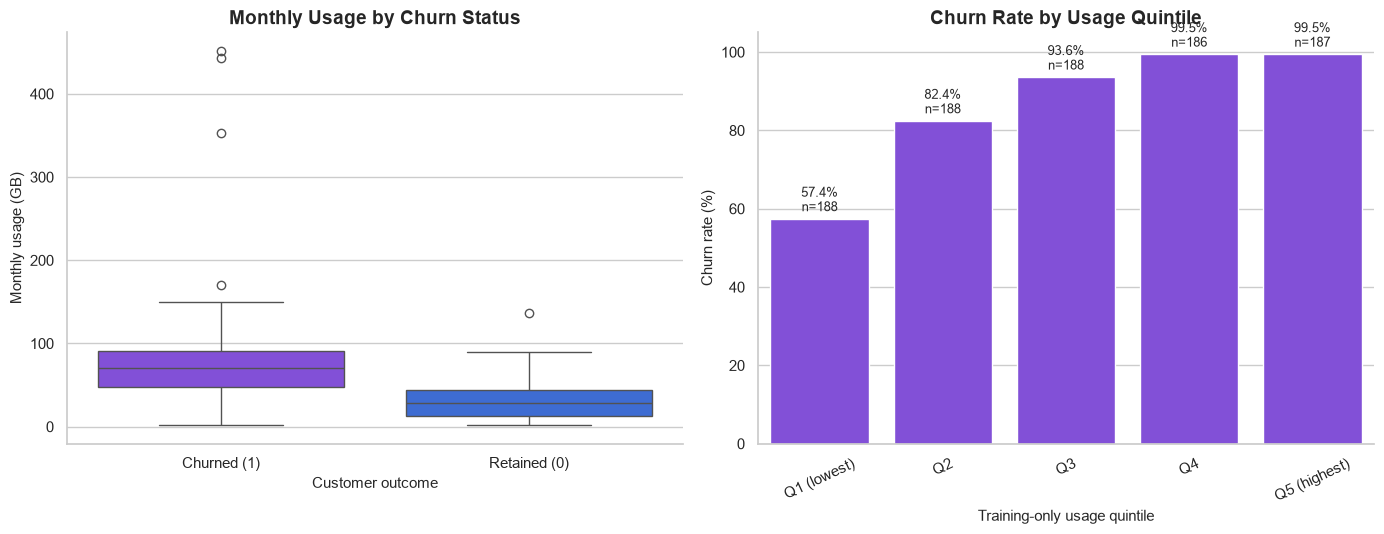

Saved: reports\figures\08_usage_churn.png


In [11]:
train_df["usage_quintile_eda"], usage_edges = pd.qcut(
    train_df["monthly_usage_gb"], q=5, labels=quintile_labels, retbins=True, duplicates="drop"
)
usage_summary = churn_summary(train_df, "usage_quintile_eda")
usage_by_target = train_df.groupby("churn")["monthly_usage_gb"].describe()[["count", "mean", "50%", "std"]]
display(usage_by_target.rename(index=status_map))
print(f"Training-only quintile edges: {np.round(usage_edges, 2).tolist()}")
display(usage_summary)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=plot_data, x="churn_status", y="monthly_usage_gb", hue="churn_status", palette=CHURN_COLORS, legend=False, ax=axes[0])
axes[0].set(title="Monthly Usage by Churn Status", xlabel="Customer outcome", ylabel="Monthly usage (GB)")
sns.barplot(data=usage_summary, x="usage_quintile_eda", y="churn_rate_pct", color=PURPLE, ax=axes[1])
label_rate_bars(axes[1], usage_summary)
axes[1].set(title="Churn Rate by Usage Quintile", xlabel="Training-only usage quintile", ylabel="Churn rate (%)", ylim=(0, 105))
axes[1].tick_params(axis="x", rotation=25)
sns.despine(fig=fig)
save_figure(fig, "08_usage_churn.png")

### Interpretation

Usage shows the strongest observed separation: churned customers average **71.57 GB** (median 70.75), compared with **30.38 GB** (median 28.00) for retained customers. Quintile rates rise sharply from **57.45% in Q1** to 82.45%, 93.62%, and approximately **99.5% in both Q4 and Q5**, with 186–188 observed customers per group. The rise and high-end plateau are clearly nonlinear. This could be highly useful only if usage is measured before the prediction cutoff; the near-saturation makes timing, population construction, and potential target leakage important business questions. Twenty-three training usage values are missing, and extreme usage may affect summaries.

## 12. Payment method versus churn

,payment_method,customer_count,churn_count,churn_rate_pct
0,Bank transfer,243,215,88.48
2,Electronic check,318,276,86.79
1,Credit card,270,229,84.81
3,Mailed check,129,109,84.50


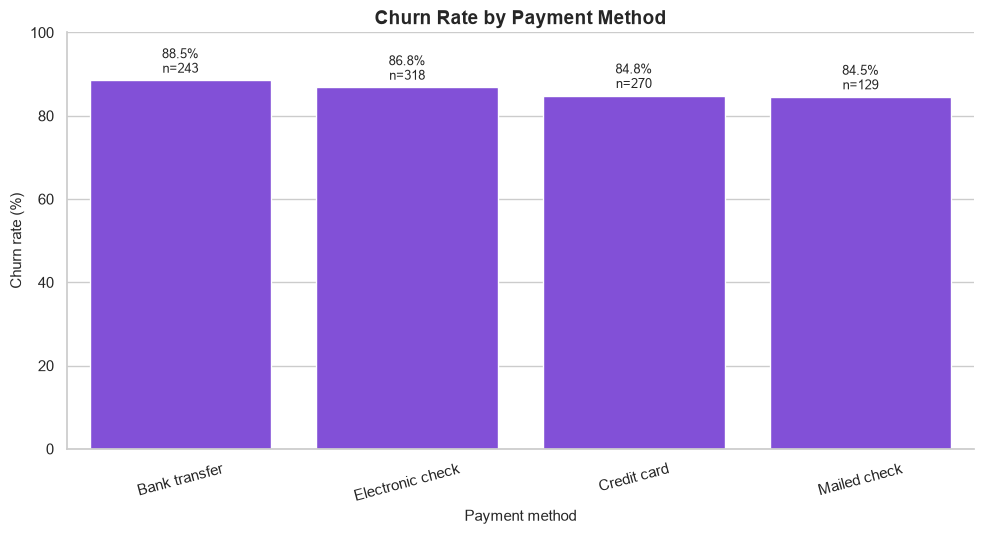

Saved: reports\figures\09_payment_method_churn.png


In [12]:
payment_summary = churn_summary(train_df, "payment_method").sort_values("churn_rate_pct", ascending=False)
display(payment_summary)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=payment_summary, x="payment_method", y="churn_rate_pct", order=payment_summary["payment_method"], color=PURPLE, ax=ax)
label_rate_bars(ax, payment_summary)
ax.set(title="Churn Rate by Payment Method", xlabel="Payment method", ylabel="Churn rate (%)", ylim=(0, 100))
ax.tick_params(axis="x", rotation=15)
sns.despine(ax=ax)
save_figure(fig, "09_payment_method_churn.png")

### Interpretation

Bank transfer has the highest observed churn rate at **88.48% (215 of 243)**, followed by electronic check at 86.79%. Credit card and mailed check are lower at 84.81% and 84.50%. The full spread is only about four percentage points, much smaller than the contract or usage differences. Payment method may provide modest context, but customer selection into a method prevents a causal interpretation.

## 13. Numerical correlation overview

Pearson correlation describes linear association only. It can miss the grouped nonlinear patterns above and does not replace multivariable analysis.

,correlation_with_churn
satisfaction_score,-0.10
senior_citizen,-0.02
tenure_months,-0.02
discount_pct,-0.00
age,-0.00
total_charges,0.02
monthly_charges,0.05
late_payments_last_12m,0.06
complaints_last_12m,0.06
monthly_usage_gb,0.36


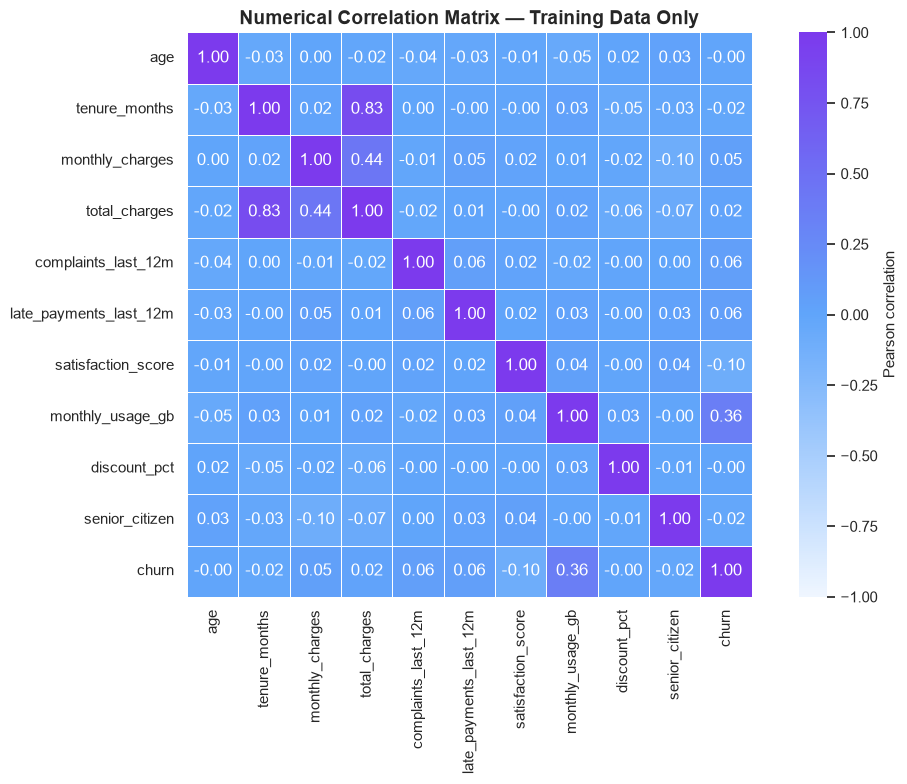

Saved: reports\figures\10_numerical_correlation_heatmap.png


In [13]:
correlation_columns = [*numerical_features, "senior_citizen", "churn"]
correlation_matrix = train_df[correlation_columns].corr(numeric_only=True)
display(correlation_matrix["churn"].sort_values().rename("correlation_with_churn").to_frame())
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(correlation_matrix, cmap=BLUE_PURPLE_CMAP, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Numerical Correlation Matrix — Training Data Only")
save_figure(fig, "10_numerical_correlation_heatmap.png")

### Interpretation

Monthly usage has the largest linear correlation with churn (**r = 0.364**). Satisfaction is next in absolute size at **r = −0.098**; complaints and late payments are each near +0.06, monthly charges +0.05, and tenure −0.016. These small coefficients do not mean the variables are useless: the charge and tenure charts show non-monotonic group rates, and interactions may carry information that a single linear coefficient misses. Correlations are computed pairwise with available training values and do not establish causality.

## 14. Interaction 1 — Contract type × tenure stage

Broader 24-month stages keep every interaction cell reasonably sized and are defined without target information.

tenure_stage_eda,1–24,25–48,49–72
contract_type,,,
Month-to-month,90.31,93.60,89.69
One year,80.22,78.48,81.33
Two year,83.33,77.08,75.56


tenure_stage_eda,1–24,25–48,49–72
contract_type,,,
Month-to-month,196,172,194
One year,91,79,75
Two year,60,48,45


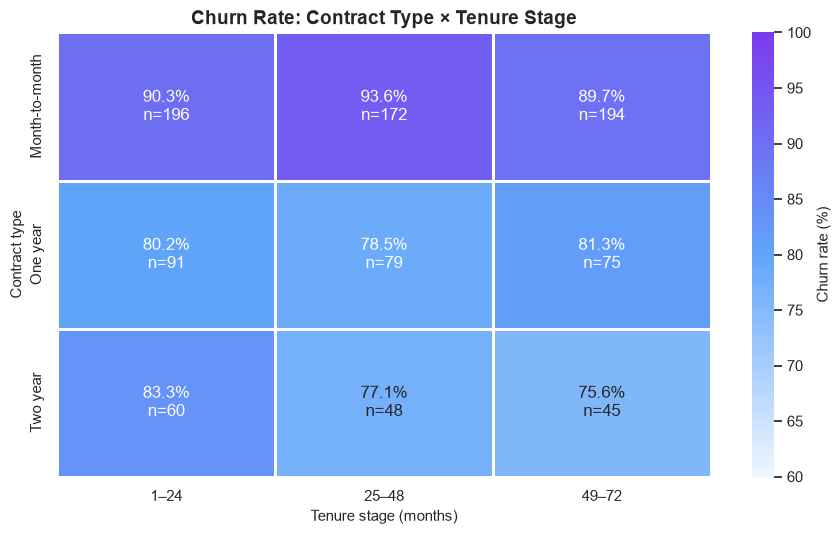

Saved: reports\figures\11_contract_tenure_interaction.png


In [14]:
tenure_stage_labels = ["1–24", "25–48", "49–72"]
train_df["tenure_stage_eda"] = pd.cut(train_df["tenure_months"], bins=[0, 24, 48, 72], labels=tenure_stage_labels, include_lowest=True)
contract_tenure_rate = train_df.pivot_table(index="contract_type", columns="tenure_stage_eda", values="churn", aggfunc="mean", observed=True) * 100
contract_tenure_count = train_df.pivot_table(index="contract_type", columns="tenure_stage_eda", values="churn", aggfunc="size", observed=True)
contract_tenure_rate = contract_tenure_rate.loc[contract_order, tenure_stage_labels]
contract_tenure_count = contract_tenure_count.loc[contract_order, tenure_stage_labels]
interaction_annotations = contract_tenure_rate.copy().astype(object)
for row in interaction_annotations.index:
    for column in interaction_annotations.columns:
        interaction_annotations.loc[row, column] = f"{contract_tenure_rate.loc[row, column]:.1f}%\nn={int(contract_tenure_count.loc[row, column])}"
display(contract_tenure_rate)
display(contract_tenure_count)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(contract_tenure_rate, annot=interaction_annotations, fmt="", cmap=BLUE_PURPLE_CMAP, vmin=60, vmax=100, linewidths=1, cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set(title="Churn Rate: Contract Type × Tenure Stage", xlabel="Tenure stage (months)", ylabel="Contract type")
save_figure(fig, "11_contract_tenure_interaction.png")

### Interpretation

Month-to-month customers remain high-risk in every stage: **90.31%, 93.60%, and 89.69%** across 1–24, 25–48, and 49–72 months. Two-year rates decline from **83.33%** in the first stage to 77.08% and 75.56%; one-year rates remain near 78–81%. Cell sizes range from 45 to 196, so all combinations have useful support, although uncertainty is greater in the smaller two-year cells. Contract differences persist within tenure stages, while the effect of tenure is not the same for every contract—evidence that a future contract–tenure interaction may be worth validating.

## 15. Interaction 2 — Satisfaction × complaints

Broader satisfaction and complaint groups avoid interpreting the smallest raw levels as stable patterns. Missing satisfaction values are excluded from this chart.

satisfaction_group_eda,≤6,>6–8,>8–10
complaint_group_eda,,,
0,87.92,85.34,76.07
1,95.60,84.21,88.46
2+,83.33,93.55,82.35


satisfaction_group_eda,≤6,>6–8,>8–10
complaint_group_eda,,,
0,149,191,117
1,91,152,78
2+,48,62,34


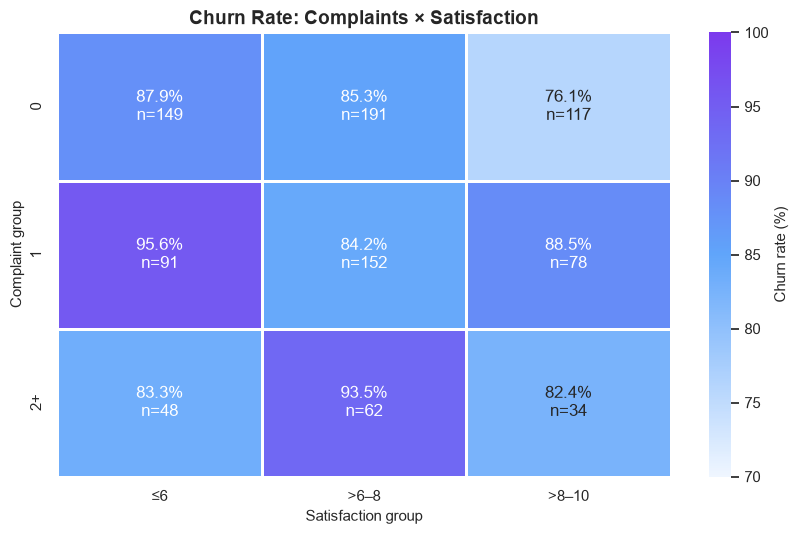

Saved: reports\figures\12_satisfaction_complaints_interaction.png


In [15]:
satisfaction_group_labels = ["≤6", ">6–8", ">8–10"]
complaint_group_labels = ["0", "1", "2+"]
train_df["satisfaction_group_eda"] = pd.cut(train_df["satisfaction_score"], bins=[0, 6, 8, 10], labels=satisfaction_group_labels, include_lowest=True)
train_df["complaint_group_eda"] = pd.cut(train_df["complaints_last_12m"], bins=[-1, 0, 1, 5], labels=complaint_group_labels)
sat_complaint_rate = train_df.pivot_table(index="complaint_group_eda", columns="satisfaction_group_eda", values="churn", aggfunc="mean", observed=True) * 100
sat_complaint_count = train_df.pivot_table(index="complaint_group_eda", columns="satisfaction_group_eda", values="churn", aggfunc="size", observed=True)
sat_complaint_rate = sat_complaint_rate.loc[complaint_group_labels, satisfaction_group_labels]
sat_complaint_count = sat_complaint_count.loc[complaint_group_labels, satisfaction_group_labels]
sat_annotations = sat_complaint_rate.copy().astype(object)
for row in sat_annotations.index:
    for column in sat_annotations.columns:
        sat_annotations.loc[row, column] = f"{sat_complaint_rate.loc[row, column]:.1f}%\nn={int(sat_complaint_count.loc[row, column])}"
display(sat_complaint_rate)
display(sat_complaint_count)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(sat_complaint_rate, annot=sat_annotations, fmt="", cmap=BLUE_PURPLE_CMAP, vmin=70, vmax=100, linewidths=1, cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set(title="Churn Rate: Complaints × Satisfaction", xlabel="Satisfaction group", ylabel="Complaint group")
save_figure(fig, "12_satisfaction_complaints_interaction.png")

### Interpretation

Among customers with no complaints, churn falls from **87.92% at satisfaction ≤6 (n=149)** to **76.07% above 8 (n=117)**. With one complaint, the low-satisfaction rate is 95.60% (n=91), while the highest-satisfaction group is still elevated at 88.46% (n=78). The 2+ complaint, middle-satisfaction cell reaches 93.55% (n=62). All cells contain at least 34 customers, but the pattern is not uniformly ordered, suggesting combined context rather than a simple additive rule. Timing and measurement definitions must be verified before either field is used predictively.

## 16. Unusual observations and unresolved quality questions

IQR flags are recalculated on the training partition only. Aggregate checks avoid exposing customer identifiers. No observation is removed or modified.

In [16]:
outlier_flags = pd.DataFrame(False, index=train_df.index, columns=numerical_features)
outlier_rows = []
for column in numerical_features:
    values = train_df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags = train_df[column].lt(lower) | train_df[column].gt(upper)
    outlier_flags[column] = flags
    flagged_values = train_df.loc[flags, column]
    outlier_rows.append({
        "column": column, "lower_bound": lower, "upper_bound": upper,
        "flagged_count": int(flags.sum()),
        "flagged_min": flagged_values.min() if flags.any() else np.nan,
        "flagged_max": flagged_values.max() if flags.any() else np.nan,
    })
display(pd.DataFrame(outlier_rows).set_index("column"))

current_rate_total = train_df["monthly_charges"] * train_df["tenure_months"]
relative_charge_difference = (train_df["total_charges"] - current_rate_total).abs() / current_rate_total.replace(0, np.nan)
unusual_summary = pd.Series({
    "unique_rows_with_IQR_flag": int(outlier_flags.any(axis=1).sum()),
    "field_level_IQR_flags": int(outlier_flags.sum().sum()),
    "total_charge_difference_over_50pct": int(relative_charge_difference.gt(0.50).sum()),
    "no_internet_but_positive_usage": int(((train_df["internet_service"] == "No") & train_df["monthly_usage_gb"].gt(0)).sum()),
    "no_internet_but_tech_support_yes": int(((train_df["internet_service"] == "No") & (train_df["tech_support"] == "Yes")).sum()),
}, name="training_records")
display(unusual_summary.to_frame())
print("Extreme observed values (training aggregate only):")
display(train_df[["monthly_charges", "total_charges", "monthly_usage_gb"]].agg(["min", "max"]))

,lower_bound,upper_bound,flagged_count,flagged_min,flagged_max
column,,,,,
age,-10.50,105.50,0,NaN,NaN
tenure_months,-36.00,108.00,0,NaN,NaN
monthly_charges,5.93,134.78,8,136.90,235.01
total_charges,"-3,033.82","7,856.98",11,"7,922.20","8,853.76"
complaints_last_12m,-1.50,2.50,35,3.00,5.00
late_payments_last_12m,-1.50,2.50,39,3.00,4.00
satisfaction_score,2.25,11.45,9,1.60,2.20
monthly_usage_gb,-29.40,158.60,4,169.80,451.30
discount_pct,-12.00,29.29,1,32.89,32.89


,training_records
unique_rows_with_IQR_flag,97
field_level_IQR_flags,107
total_charge_difference_over_50pct,4
no_internet_but_positive_usage,122
no_internet_but_tech_support_yes,48


Extreme observed values (training aggregate only):


,monthly_charges,total_charges,monthly_usage_gb
min,20.00,22.73,2.00
max,235.01,"8,853.76",451.30


### Interpretation

The training data has **107 field-level IQR flags across 97 customers**. Notable ranges include monthly charges up to 235.01, total charges up to 8,853.76, and usage up to 451.3 GB; these may be legitimate high-value behavior rather than errors. Four training records have a total-charge difference above 50% from the simple current-rate × tenure comparison. Also, 122 of 123 `internet_service = No` records with observed usage show positive usage, and 48 have technical support. These combinations require definitions from the business or source system. They are retained and must not be corrected based on EDA alone.

## 17. Potential Phase 4 feature ideas — not implemented

These are hypotheses for later validation inside training folds. Availability must be confirmed at the prediction cutoff before implementation.

In [17]:
feature_ideas = pd.DataFrame([
    {"proposed_name": "tenure_stage", "source_columns": "tenure_months", "business_rationale": "Represent nonlinear lifecycle stages", "expected_usefulness": "Capture band differences and support contract interactions", "leakage_concern": "Derive cut points inside training data or use fixed business stages", "prediction_time": "Yes, if tenure is current"},
    {"proposed_name": "contract_tenure_interaction", "source_columns": "contract_type, tenure_months", "business_rationale": "Contract association changes across tenure stages", "expected_usefulness": "Allow contract-specific lifecycle effects", "leakage_concern": "No target-derived encoding; learn categories in pipeline", "prediction_time": "Yes"},
    {"proposed_name": "high_usage_or_usage_band", "source_columns": "monthly_usage_gb", "business_rationale": "Usage shows a steep nonlinear risk gradient", "expected_usefulness": "Represent threshold/plateau behavior", "leakage_concern": "Confirm usage window ends before outcome; fit quantiles on training fold only", "prediction_time": "Unresolved until timing is confirmed"},
    {"proposed_name": "satisfaction_complaint_interaction", "source_columns": "satisfaction_score, complaints_last_12m", "business_rationale": "Complaint risk differs across satisfaction groups", "expected_usefulness": "Capture combined service-friction context", "leakage_concern": "Confirm both fields predate prediction cutoff", "prediction_time": "Likely, timing must be confirmed"},
    {"proposed_name": "repeated_payment_difficulty", "source_columns": "late_payments_last_12m", "business_rationale": "2+ late payments show a higher churn rate", "expected_usefulness": "Represent nonlinear escalation in payment behavior", "leakage_concern": "Use only events known before scoring", "prediction_time": "Yes if event window is historical"},
    {"proposed_name": "charge_tenure_consistency", "source_columns": "total_charges, monthly_charges, tenure_months", "business_rationale": "Summarize billing history relative to the current rate", "expected_usefulness": "May capture discounts, price changes, or anomalies", "leakage_concern": "Field definitions unresolved; avoid until business validation", "prediction_time": "Unresolved"},
])
display(feature_ideas)

,proposed_name,source_columns,business_rationale,expected_usefulness,leakage_concern,prediction_time
0,tenure_stage,tenure_months,Represent nonlinear lifecycle stages,Capture band differences and support contract ...,Derive cut points inside training data or use ...,"Yes, if tenure is current"
1,contract_tenure_interaction,"contract_type, tenure_months",Contract association changes across tenure stages,Allow contract-specific lifecycle effects,No target-derived encoding; learn categories i...,Yes
2,high_usage_or_usage_band,monthly_usage_gb,Usage shows a steep nonlinear risk gradient,Represent threshold/plateau behavior,Confirm usage window ends before outcome; fit ...,Unresolved until timing is confirmed
3,satisfaction_complaint_interaction,"satisfaction_score, complaints_last_12m",Complaint risk differs across satisfaction groups,Capture combined service-friction context,Confirm both fields predate prediction cutoff,"Likely, timing must be confirmed"
4,repeated_payment_difficulty,late_payments_last_12m,2+ late payments show a higher churn rate,Represent nonlinear escalation in payment beha...,Use only events known before scoring,Yes if event window is historical
5,charge_tenure_consistency,"total_charges, monthly_charges, tenure_months",Summarize billing history relative to the curr...,"May capture discounts, price changes, or anoma...",Field definitions unresolved; avoid until busi...,Unresolved


## 18. Evidence-based summary

- Usage has the strongest observed association and a steep nonlinear rise, but its measurement timing must be verified before it can become a predictor.
- Month-to-month contracts show consistently higher churn across tenure stages.
- Lower satisfaction, repeated late payments, and 3+ complaints are associated with higher churn in supported grouped comparisons.
- Monthly charges show a modest non-monotonic relationship; tenure alone is weak and non-monotonic.
- Payment-method differences are comparatively small.
- Interactions suggest that contract context and service-friction combinations may matter, but they require validation rather than automatic feature creation.

The class imbalance, missing measurements, unresolved definitions, and observational design limit interpretation. None of these relationships demonstrates causation.

## 19. Verification

The final checks confirm that the cleaned dataset was not modified and that every planned figure exists.

In [18]:
expected_figures = [
    "01_churn_distribution.png", "02_contract_churn.png", "03_tenure_churn.png",
    "04_monthly_charges_churn.png", "05_satisfaction_churn.png",
    "06_complaints_churn.png", "07_late_payments_churn.png",
    "08_usage_churn.png", "09_payment_method_churn.png",
    "10_numerical_correlation_heatmap.png", "11_contract_tenure_interaction.png",
    "12_satisfaction_complaints_interaction.png",
]
missing_figures = [name for name in expected_figures if not (FIGURES_DIR / name).is_file()]
cleaned_sha256_after = hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest()
assert not missing_figures, f"Missing figures: {missing_figures}"
assert cleaned_sha256_before == cleaned_sha256_after
assert len(train_df) == 960 and len(test_indices) == 240
assert set(train_indices).isdisjoint(test_indices)
print(f"Figures verified: {len(expected_figures)}")
print(f"Cleaned dataset unchanged: {cleaned_sha256_before == cleaned_sha256_after}")
print("Target-aware EDA rows: training indices only")
print("Models fitted: 0; predictions generated: 0")

Figures verified: 12
Cleaned dataset unchanged: True
Target-aware EDA rows: training indices only
Models fitted: 0; predictions generated: 0


## Phase 3 conclusion

Training-only EDA is complete and the final test partition remains sealed. The findings support hypotheses for Phase 4, but no feature has been engineered or selected yet. Stop here until Feature Engineering is approved.